# Actividad 2 - Gráficos y funciones


**Participante:** Elmer Quispe Salazar  
**Usuario de GitHub:** `qselmer`  
**Lenguaje:** Python  
**Fecha:** 12 de noviembre de 2026

**Objetivos:** elaborar visualizaciones, documentar una función y registrar los cambios con Git.

Se reutilizan los seis registros de la Actividad 1.

## Verificación del entorno


In [1]:
from pathlib import Path
import importlib.util
import sys

# Verificación sin modificar el Python del sistema (incluido el gestionado por uv).
necesarios = ("pandas", "matplotlib")
faltantes = [paquete for paquete in necesarios if importlib.util.find_spec(paquete) is None]
print("Python del kernel:", sys.executable)
if faltantes:
    raise RuntimeError(
        "Faltan dependencias: " + ", ".join(faltantes)
        + ". Crea el entorno desde la raíz del repositorio con "
        + "scripts/setup_windows.ps1 (Windows) o bash scripts/setup_unix.sh "
        + "(macOS/Linux) y selecciona el kernel Python (preOHW2026). "
        + "En GitHub Codespaces se instalan al crear el Codespace."
    )
print("Dependencias disponibles. Puedes ejecutar el notebook.")

Python del kernel: D:\.qselmer\OceanHackWeek2026\preOHW2026\.venv\Scripts\python.exe
Dependencias disponibles. Puedes ejecutar el notebook.


## 1. Carga y comprobación de datos

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidatos = [ Path("../01_actividad/datos/datos_ejemplo.csv")]
archivo = next((p for p in candidatos if p.exists()), None)
if archivo is None:
    raise FileNotFoundError("No se encontró el CSV de la actividad 1.")
df = pd.read_csv(archivo)
columnas = {"mes", "temperatura_c", "clorofila_mg_m3"}
assert columnas.issubset(df.columns), "Columnas requeridas no encontradas"
print(f"Archivo: {archivo} | {len(df)} registros")
display(df.head())

Archivo: ..\01_actividad\datos\datos_ejemplo.csv | 6 registros


,mes,temperatura_c,clorofila_mg_m3
0,enero,19.1,2.3
1,febrero,20.2,2.1
2,marzo,20.5,1.8
3,abril,19.4,2.5
4,mayo,18.3,3.1


## 2. Visualizaciones

Se emplean gráficos de línea para describir el orden de los seis meses y un diagrama de dispersión para explorar la asociación aparente entre variables. Las escalas y unidades se indican explícitamente.

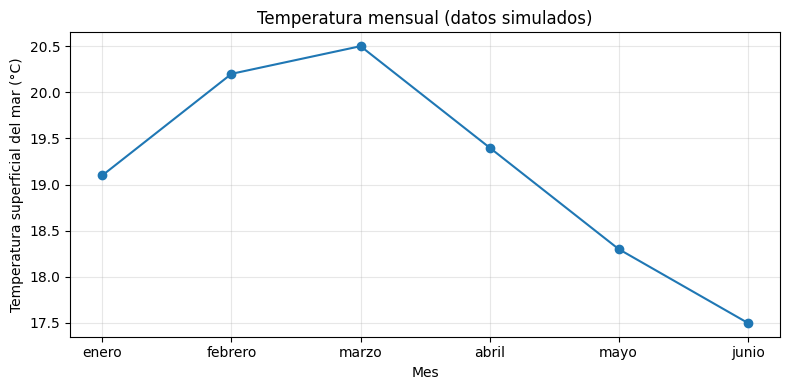

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df["mes"], df["temperatura_c"], marker="o")
ax.set(xlabel="Mes", ylabel="Temperatura superficial del mar (°C)", title="Temperatura mensual (datos simulados)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

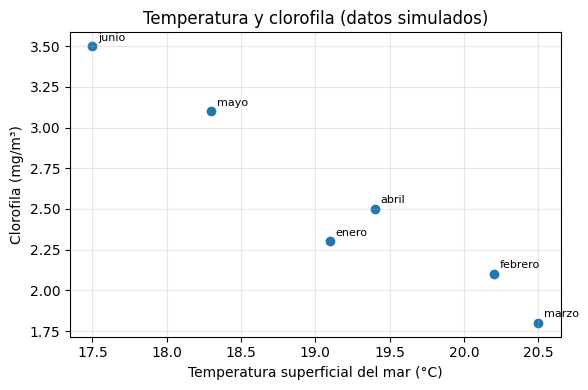

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["temperatura_c"], df["clorofila_mg_m3"])
for _, fila in df.iterrows():
    ax.annotate(fila["mes"], (fila["temperatura_c"], fila["clorofila_mg_m3"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="Temperatura superficial del mar (°C)", ylabel="Clorofila (mg/m³)", title="Temperatura y clorofila (datos simulados)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Función propia

La siguiente función calcula el promedio de una serie numérica y omite los valores ausentes. Si no hay datos válidos, devuelve `NaN`.

**Parámetros:** `valores`, secuencia de números. **Retorno:** `float`.

In [5]:
def promedio_valido(valores):
    """Calcula la media aritmética ignorando valores faltantes.

    Parámetros
    ----------
    valores : secuencia de números
        Valores a promediar; puede contener NaN.

    Retorna
    -------
    float
        Media de los valores válidos, o NaN si todos son faltantes.
    """
    serie = pd.to_numeric(pd.Series(valores), errors="coerce").dropna()
    return float(serie.mean()) if not serie.empty else float("nan")

media_tsm = promedio_valido(df["temperatura_c"])
media_clorofila = promedio_valido(df["clorofila_mg_m3"])
print(f"Temperatura media: {media_tsm:.2f} °C")
print(f"Clorofila media: {media_clorofila:.2f} mg/m³")
assert abs(promedio_valido([1, 2, None, 3]) - 2.0) < 1e-12

Temperatura media: 19.17 °C
Clorofila media: 2.55 mg/m³




Los gráficos permiten visualizar cambios entre meses y comparar descriptivamente ambas variables. Como se trata de **solo seis valores inventados**, no se deben generalizar los patrones, calcular tendencias de largo plazo ni atribuir causalidad.

